# Moving through the code

*Question 2 of the latent-space analysis.*

The first notebook showed *what* the latent code of a bar remembers: mostly a faithful picture
of its notes. This one asks how that information is *organised*. If we take the code of a bar
and nudge it in some direction, does the music change in one understandable way: higher,
busier, more dissonant? Or does everything change at once?

This matters for two reasons. It tells us how the model "thinks" about music: in terms of
simple musical qualities, or as an opaque tangle. And when a direction works, it becomes a
control knob we can turn, and hear.

We use the **compact** model (β = 0.1) throughout, as the first notebook found its space to be
the tidier of the two, and compare with the **detailed** model (β = 0.01) where it's
informative. All bars come from the validation pieces, which the models never saw during
training. Running this notebook takes about 15 minutes on a laptop CPU.

In [1]:
import os
from pathlib import Path

root = Path.cwd()
while not (root / "pyproject.toml").exists():
    root = root.parent
os.chdir(root)  # paths below are relative to the repository root

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pianotree_dcml.analysis.audio import play, save_wav, synthesize, to_midi
from pianotree_dcml.analysis.decode import decode, lerp, slerp
from pianotree_dcml.analysis.directions import (
    consistency, mean_difference_direction, move_and_measure, spread_along, unit)
from pianotree_dcml.analysis.encode import dataset_for, encode_notes, load_embeddings
from pianotree_dcml.analysis.features import bar_features, notes_table
from pianotree_dcml.analysis.plots import plot_bars
from pianotree_dcml.analysis.probes import detector_accuracy
from pianotree_dcml.analysis.transform import split_notes, transpose
from pianotree_dcml.metrics import note_counts
from pianotree_dcml.train import load_checkpoint

OUT = Path("notebooks/outputs/q2")  # figures and sounds, e.g. for a blog post
OUT.mkdir(parents=True, exist_ok=True)

RUNS = {"compact (β = 0.1)": "runs/full", "detailed (β = 0.01)": "runs/full_beta0.01"}
COLORS = {"compact (β = 0.1)": "tab:blue", "detailed (β = 0.01)": "tab:orange"}
models = {name: load_checkpoint(f"{run}/best.pt")[0] for name, run in RUNS.items()}
codes = {name: load_embeddings(f"{run}/embeddings.npz").mean for name, run in RUNS.items()}
COMPACT = "compact (β = 0.1)"
model, z = models[COMPACT], codes[COMPACT]

bars = load_embeddings("runs/full/embeddings.npz").bars
dataset = dataset_for(load_embeddings("runs/full/embeddings.npz"))
features = bar_features(dataset.notes_table(), bars.bar_len)
valid = (bars.split == "valid").to_numpy()
train = ~valid

# All experiments use validation bars of 16 steps (4/4 and 2/2), so that bars can be compared
# and moved bars can be measured on the same length.
pool = np.flatnonzero(valid & (bars.bar_len == 16).to_numpy())
rng = np.random.default_rng(0)
sample = rng.choice(pool, 300, replace=False)
real = features.loc[pool]


def note_f1(a, b):
    return note_counts(a, b).scores()["note_f1"]


def bar_label(i):
    return f"{bars.composer[i]}, {bars.piece[i]} (bar {bars.mn[i]})"

print(f"{len(pool)} validation bars of 16 steps; experiments use {len(sample)} of them")

3067 validation bars of 16 steps; experiments use 300 of them


## 1. Turning knobs: higher, busier, more dissonant

To find the direction of, say, "higher" in the code, we take the bars of the training pieces,
average the codes of the 25% highest bars and the codes of the 25% lowest, and draw an arrow
from one average to the other. Then we take bars from the validation pieces, move their codes
along that arrow in steps, decode them, and measure what changed.

Steps are measured in *spreads*: one spread is the typical difference between two bars along
that direction, so moving from −2 to +2 spreads goes from an unusually low to an unusually high
bar. We do this for four properties: **register** (how high the notes are), **number of notes**,
**note length**, and **dissonance** (the share of notes starting together that sound tense: a
semitone, a whole tone, a tritone or a seventh apart).

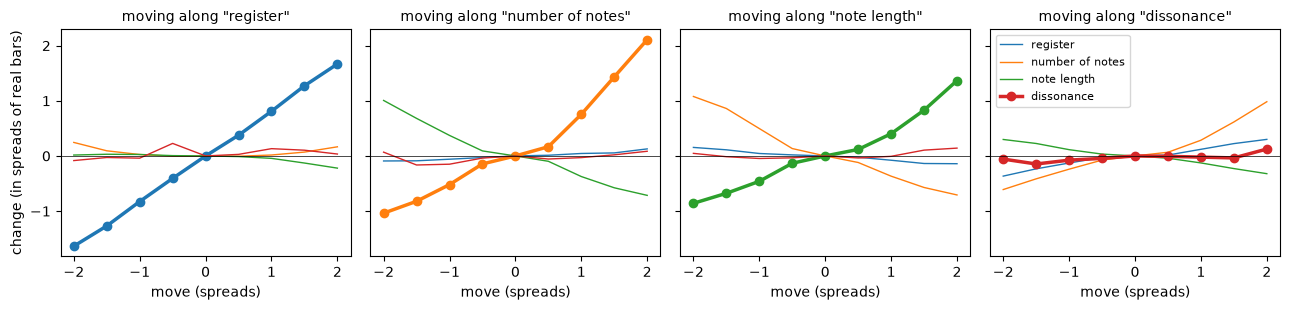

,register,number of notes,note length,dissonance
move (spreads),,,,
-2.0,51.20,6.37,1.79,0.13
-1.5,53.77,8.33,2.28,0.12
-1.0,56.86,11.07,2.86,0.13
-0.5,59.80,14.47,3.75,0.13
0.0,62.64,15.77,4.10,0.14
0.5,65.27,17.29,4.42,0.14
1.0,68.31,22.61,5.19,0.14
1.5,71.54,28.76,6.34,0.13
2.0,74.31,34.87,7.78,0.16


How much the directions overlap (1 = same direction, 0 = unrelated):


,register,number of notes,note length,dissonance
register,1.00,0.06,0.11,0.11
number of notes,0.06,1.00,0.64,0.67
note length,0.11,0.64,1.00,0.40
dissonance,0.11,0.67,0.40,1.00


In [2]:
PROPERTIES = {"register": "pitch_mean", "number of notes": "n_notes",
              "note length": "duration_mean", "dissonance": "dissonance"}
directions = {p: mean_difference_direction(z[train], features[c].to_numpy()[train])
              for p, c in PROPERTIES.items()}
amounts = np.linspace(-2, 2, 9)
real_std = real[list(PROPERTIES.values())].std()

moved = {}
for p in PROPERTIES:
    step = spread_along(z[train], directions[p])
    moved[p] = move_and_measure(model, z[sample[:150]], directions[p], amounts * step, bar_len=16)
    moved[p]["amount"] = (moved[p].amount / step).round(2)  # back to spreads

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, p in zip(axes, PROPERTIES):
    means = moved[p].groupby("amount")[list(PROPERTIES.values())].mean()
    change = (means - means.loc[0.0]) / real_std  # in units of the real bars' spread
    for q, column in PROPERTIES.items():
        ax.plot(amounts, change[column], marker="o" if q == p else None,
                linewidth=2.5 if q == p else 1, label=q)
    ax.axhline(0, color="k", linewidth=0.5)
    ax.set_title(f'moving along "{p}"', fontsize=10)
    ax.set_xlabel("move (spreads)")
axes[0].set_ylabel("change (in spreads of real bars)")
axes[-1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "directions.png", dpi=150)
plt.show()

table = pd.DataFrame({p: moved[p].groupby("amount")[c].mean() for p, c in PROPERTIES.items()})
table.index.name = "move (spreads)"
display(table.round(2))
cosines = pd.DataFrame({a: {b: abs(directions[a] @ directions[b]) for b in PROPERTIES}
                        for a in PROPERTIES})
print("How much the directions overlap (1 = same direction, 0 = unrelated):")
display(cosines.round(2))

Each panel moves bars along one direction (thick line) and tracks all four properties.

**"Higher" is a clean knob.** Moving along it raises the average pitch steadily, by almost two
octaves from −2 to +2 spreads, while the other properties barely move.

**"Busier" is a knob too**, from about 6 to 35 notes per bar. The notes get shorter at the
same time, but that is built into the music rather than a side effect: a bar has a fixed
length, so more notes means shorter ones. The "note length" direction is the same knob turned
the other way (the two directions overlap a lot).

**"More dissonant" is not a knob of its own.** Moving along it raises dissonance only slightly,
and mostly makes bars busier: its direction overlaps strongly with "number of notes". In the
code, dissonance is tangled with density: busy bars tend to have more tense combinations, and
the model hasn't separated the two.

Listen to one bar moved along each direction, from −2 to +2 spreads. The bar was picked among
those the model plays back perfectly, so that what you hear is the effect of the move.

Example bar: Ludwig van Beethoven, 05-3 (bar 16)


moving along "register": -2, -1, +0, +1, +2 spreads


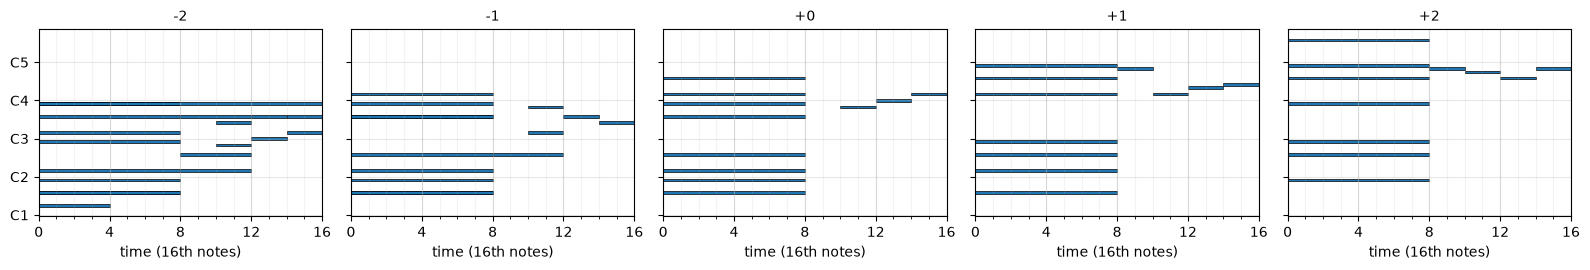

moving along "number of notes": -2, -1, +0, +1, +2 spreads


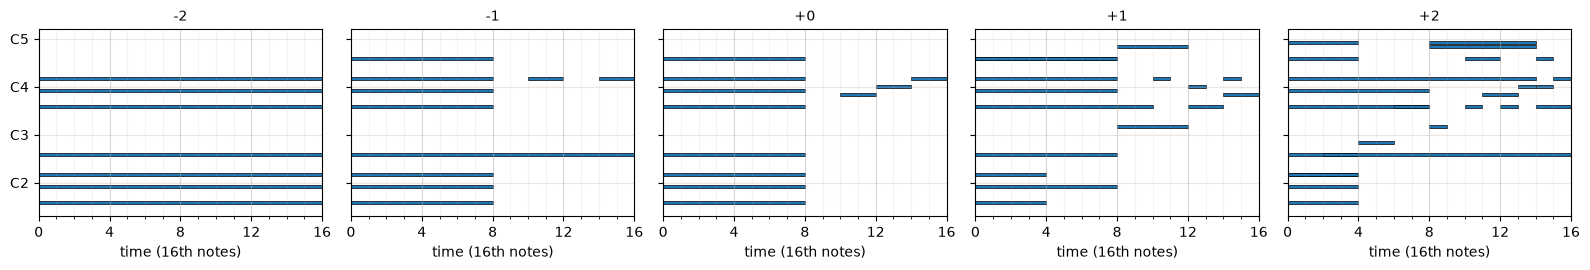

moving along "dissonance": -2, -1, +0, +1, +2 spreads


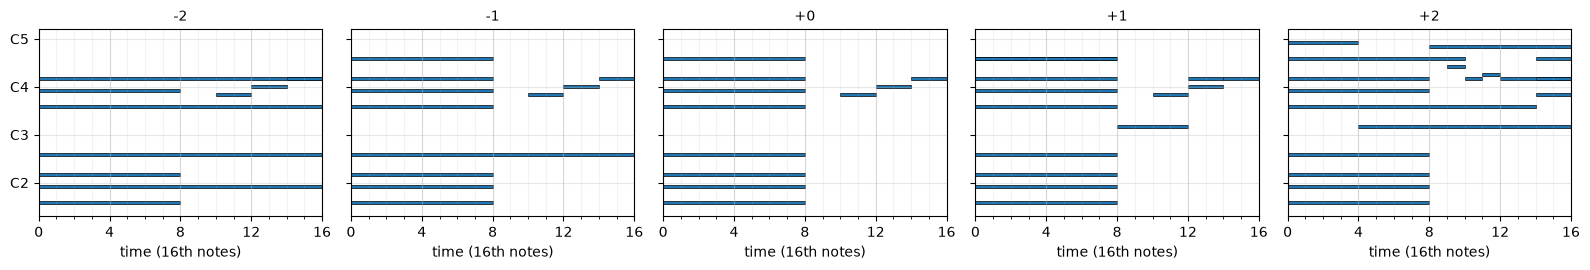

In [3]:
candidates = [i for i in sample[150:]
              if 8 <= features.n_notes[i] <= 14 and decode(model, z[i])[0] == dataset.notes(i)]
example = candidates[0]
print("Example bar:", bar_label(example))
steps = np.array([-2, -1, 0, 1, 2])
for p in ["register", "number of notes", "dissonance"]:
    spread = spread_along(z[train], directions[p])
    path = decode(model, z[example] + steps[:, None] * spread * directions[p])
    name = p.replace(" ", "_")
    print(f'moving along "{p}": {", ".join(f"{s:+d}" for s in steps)} spreads')
    fig = plot_bars(path, [f"{s:+d}" for s in steps], [16] * 5)
    fig.savefig(OUT / f"knob_{name}.png", dpi=150)
    plt.show()
    save_wav(synthesize(path, [16] * 5, gap_steps=4), OUT / f"knob_{name}.wav")
    to_midi(path, OUT / f"knob_{name}.mid", [16] * 5, gap_steps=4)
    display(play(path, [16] * 5, gap_steps=4))

## 2. A stricter test: transposing and speeding up

The directions above are averages: they tell us where high bars sit compared with low ones,
not whether the model represents "the same music, but higher". For that, we need a change whose
effect we know exactly. **Transposing** a bar (moving every note up by the same number of
semitones) keeps the music identical, only higher. **Splitting** every note into two notes of
half the length keeps the same harmony with a busier rhythm.

We apply each change to 300 bars, encode the changed bars, and look at how their codes moved.
If the model stored "melody shape" and "key" separately, transposing should move every code by
the same arrow. We measure how aligned each bar's move is with the average move (the cosine:
1 when perfectly aligned, 0 when unrelated).

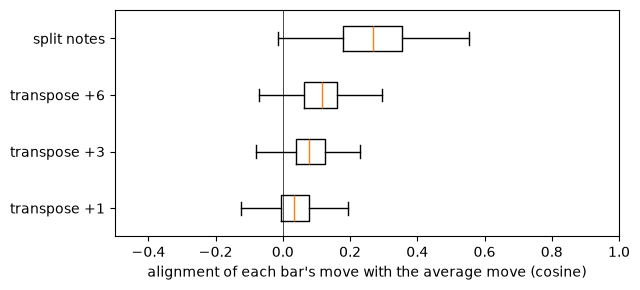

Average share of a bar's move that follows the common direction (cosine squared): {'transpose +1': '0%', 'transpose +3': '1%', 'transpose +6': '2%', 'split notes': '9%'}
Register direction vs transposition direction overlap: 0.85


In [4]:
originals = [dataset.notes(i) for i in sample]
z0 = z[sample]
semitones = [k for k in range(-6, 7) if k]
transposed = {k: [transpose(n, k) for n in originals] for k in semitones}
moves = {k: encode_notes(model, transposed[k])[0] - z0 for k in semitones}
per_semitone = unit(np.mean([moves[k].mean(axis=0) / k for k in semitones], axis=0))
step = np.mean([(moves[k] @ per_semitone).mean() / k for k in semitones])

split = [split_notes(n) for n in originals]
split_move = encode_notes(model, split)[0] - z0
faster = split_move.mean(axis=0)

alignment = {f"transpose {k:+d}": consistency(moves[k], np.sign(k) * per_semitone)
             for k in [1, 3, 6]}
alignment["split notes"] = consistency(split_move, faster)
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.boxplot(list(alignment.values()), orientation="horizontal", showfliers=False)
ax.set_yticks(range(1, len(alignment) + 1), list(alignment))
ax.axvline(0, color="k", linewidth=0.5)
ax.set_xlim(-0.5, 1)
ax.set_xlabel("alignment of each bar's move with the average move (cosine)")
fig.tight_layout()
fig.savefig(OUT / "alignment.png", dpi=150)
plt.show()
print("Average share of a bar's move that follows the common direction (cosine squared):",
      {name: f"{np.mean(c ** 2):.0%}" for name, c in alignment.items()})
print(f"Register direction vs transposition direction overlap: "
      f"{abs(directions['register'] @ per_semitone):.2f}")

The moves are barely aligned. When we transpose bars, each code moves in its own way, and only
a few percent of each move follows the common direction; splitting notes is somewhat more
consistent, but not much. The common direction for transposition is essentially the
"register" direction found above.

So what happens if we *use* that common direction, moving a code by the average amount for
3 semitones? We compare three things with the truly transposed bar: the moved code, the code of
the transposed bar itself (what the model does when it actually sees the transposed music), and
the original bar left alone.

In [5]:
base = decode(model, z0)

def average_pitch(bars_):
    return np.array([np.mean([p for _, p, _ in b]) if b else np.nan for b in bars_])

rows = []
for k in [-6, -3, 3, 6]:
    by_moving = decode(model, z0 + k * step * per_semitone)
    by_encoding = decode(model, z0 + moves[k])
    rows.append({
        "transposition (semitones)": k,
        "pitch change from moving the code": np.nanmean(average_pitch(by_moving) - average_pitch(base)),
        "notes right: moved code": np.mean([note_f1(a, b) for a, b in zip(by_moving, transposed[k])]),
        "notes right: encoded transposed bar": np.mean([note_f1(a, b) for a, b in zip(by_encoding, transposed[k])]),
        "notes right: original bar": np.mean([note_f1(a, b) for a, b in zip(base, transposed[k])]),
    })
display(pd.DataFrame(rows).set_index("transposition (semitones)").round(2))

by_moving = decode(model, z0 + faster)
measured = {name: bar_features(notes_table(b), pd.Series([16] * len(b)))
            for name, b in [("original", base), ("moved code", by_moving), ("truly split", split)]}
display(pd.DataFrame({name: {"notes per bar": f.n_notes.mean(), "note length": f.duration_mean.mean(),
                             "register": f.pitch_mean.mean()} for name, f in measured.items()}).round(2))
print(f"Notes right compared with the truly split bar: moved code "
      f"{np.mean([note_f1(a, b) for a, b in zip(by_moving, split)]):.2f}, encoded split bar "
      f"{np.mean([note_f1(a, b) for a, b in zip(decode(model, z0 + split_move), split)]):.2f}")

,pitch change from moving the code,notes right: moved code,notes right: encoded transposed bar,notes right: original bar
transposition (semitones),,,,
-6,-4.93,0.04,0.80,0.02
-3,-2.26,0.23,0.81,0.08
3,2.14,0.22,0.82,0.08
6,4.70,0.05,0.81,0.02


,original,moved code,truly split
notes per bar,16.17,25.58,27.36
note length,3.88,2.43,2.10
register,62.54,62.21,62.48


Notes right compared with the truly split bar: moved code 0.31, encoded split bar 0.64


Moving the code raises the pitch by roughly the requested amount for large moves (about 2 of
3 semitones, about 5 of 6), but it doesn't *transpose* the bar: for 3 semitones, only about a
quarter of the notes match the truly transposed bar, and for 6 almost none do, against about
80% when the model encodes the transposed bar itself. The move changes *which* notes are played rather than shifting them all together.
Likewise, moving along the "faster" direction makes bars busier by about the right amount without
changing their register, but doesn't reproduce the split notes.

This fits the first notebook: the code is a picture of the notes at their actual pitches, not a
melody shape plus a key. Transposing a bar is, to the model, almost like playing a different bar.
Listen to the difference: the original bar, then the truly transposed bar (3 semitones up), then
the bar decoded from the moved code.

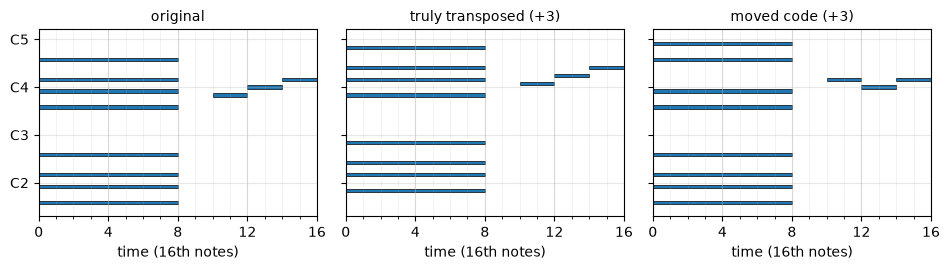

In [6]:
original = dataset.notes(example)
truly = transpose(original, 3)
moved_bar = decode(model, z[example] + 3 * step * per_semitone)[0]
versions = [original, truly, moved_bar]
fig = plot_bars(versions, ["original", "truly transposed (+3)", "moved code (+3)"], [16] * 3)
fig.savefig(OUT / "transposition.png", dpi=150)
plt.show()
save_wav(synthesize(versions, [16] * 3, gap_steps=4), OUT / "transposition.wav")
to_midi(versions, OUT / "transposition.mid", [16] * 3, gap_steps=4)
display(play(versions, [16] * 3, gap_steps=4))

## 3. Paths between two bars

Finally, we walk from one real bar to another: we draw a path between their codes, decode nine
points along it, and ask two questions. Does the music change gradually, or in one sudden jump?
And do the bars along the way sound like real music, or like noise?

We compare two kinds of path, the straight line between the two codes and *slerp*, which
follows a great circle where most of the codes live, and the two models. For each, we draw paths
between 200 random pairs of validation bars and measure:

- **evenness**: the biggest change between two consecutive steps, as a share of the whole path's
  change. With 8 steps, a perfectly even path would score 12.5%; a sudden jump, close to 100%;
- **realism of the halfway bars**: how often a detector tells them apart from real bars (50%
  means it can't), and their dissonance compared with real music.

In [7]:
pairs = rng.choice(pool, (200, 2), replace=False)
rows = []
for name in RUNS:
    for method, path_fn in [("slerp", slerp), ("straight line", lerp)]:
        paths = [decode(models[name], path_fn(codes[name][a], codes[name][b], 9)) for a, b in pairs]
        changes = np.array([[1 - note_f1(p[i], p[i + 1]) for i in range(8)] for p in paths])
        halfway = bar_features(notes_table([p[4] for p in paths]), pd.Series([16] * len(paths)))
        rows.append({"model": name, "path": method,
                     "biggest step (share of path)": (changes.max(1) / np.maximum(changes.sum(1), 1e-9)).mean(),
                     "detector on halfway bars": detector_accuracy(real, halfway),
                     "dissonance of halfway bars": halfway.dissonance.mean()})
paths_table = pd.DataFrame(rows).set_index(["model", "path"])
display(paths_table.style.format({"biggest step (share of path)": "{:.0%}",
                                  "detector on halfway bars": "{:.0%}",
                                  "dissonance of halfway bars": "{:.2f}"}))
print(f"Dissonance of real bars: {real.dissonance.mean():.2f}")

Dissonance of real bars: 0.15


Paths change fairly gradually: the biggest step is on average about a fifth of the path's total
change, for both models and both kinds of path, so there are no sudden jumps on the whole. The
difference lies in what lies between. Halfway between two real bars, the compact model with slerp
decodes bars a detector can barely tell from real music; straight lines produce more dissonant
bars, and the detailed model's halfway bars are clearly less realistic, as were its random bars
in the first notebook.

To hear a long walk, here is a path from a bar of Corelli (1680s) to a bar of one of the latest
composers in the validation set, decoded with the compact model along slerp.

from Arcangelo Corelli, op01n02b (bar 1) 
to   Pyotr Ilyich Tchaikovsky, op37a10 (bar 3)


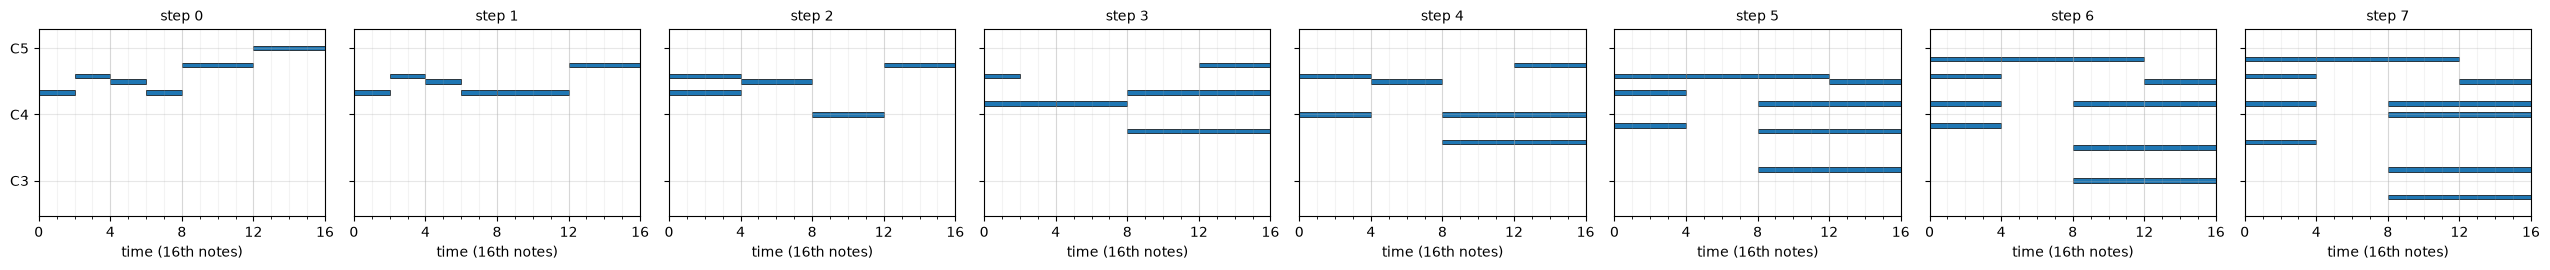

In [8]:
def well_played(corpus):
    for i in pool:
        if bars.corpus[i] == corpus and 6 <= features.n_notes[i] <= 16 \
                and decode(model, z[i])[0] == dataset.notes(i):
            return i

start = well_played("corelli")
end = next(i for c in ["medtner_tales", "debussy_suite_bergamasque", "tchaikovsky_seasons"]
           if (i := well_played(c)) is not None)
print("from", bar_label(start), "\nto  ", bar_label(end))
path = decode(model, slerp(z[start], z[end], 8))
fig = plot_bars(path, [f"step {s}" for s in range(8)], [16] * 8, ncols=8)
name = f"path_{bars.corpus[start].split('_')[0]}_to_{bars.corpus[end].split('_')[0]}"
fig.savefig(OUT / f"{name}.png", dpi=150)
plt.show()
save_wav(synthesize(path, [16] * 8, gap_steps=2), OUT / f"{name}.wav")
to_midi(path, OUT / f"{name}.mid", [16] * 8, gap_steps=2)
display(play(path, [16] * 8, gap_steps=2))

## Summary

- **Some musical qualities are simple directions in the code.** "Higher" is a clean knob, and
  "busier" (more, shorter notes) is another. Turning them changes the music in one
  understandable way, which you can hear.
- **Others are tangled.** "More dissonant" isn't a direction of its own: in the code, it goes
  along with "busier".
- **The code stores notes as they are, not "melody plus key".** Transposing a bar moves its code
  in an idiosyncratic way, and moving a code in the average direction changes the notes rather
  than shifting them. The same holds for speeding up the rhythm.
- **The space between bars is musical.** Paths between real bars change gradually, and with the
  compact model the bars halfway between are hard to tell from real music, especially along
  slerp paths.

The next question asks whether this space also says something about **who** wrote the music
and **when**: do composers and eras occupy different regions, beyond the simple properties we
measured here?